In [1]:
# Install Tiny-SIMA and the optional VLM backend into this kernel.
import importlib
import os
import shutil
import subprocess
import sys
from pathlib import Path

# Leave room for the PyTorch VLM before importing JAX.
os.environ.setdefault(
    "XLA_PYTHON_CLIENT_MEM_FRACTION",
    os.environ.get("TINY_SIMA_JAX_MEMORY_FRACTION", "0.35"),
)

if not ((3, 11) <= sys.version_info[:2] < (3, 13)):
    raise RuntimeError("Tiny-SIMA requires Python 3.11 or 3.12.")

repo_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Open this notebook from the Tiny-SIMA repository.")

cuda_override = os.environ.get("TINY_SIMA_USE_CUDA")
if cuda_override is None:
    has_cuda = (
        shutil.which("nvidia-smi") is not None
        and subprocess.run(
            ["nvidia-smi"],
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
            check=False,
        ).returncode == 0
    )
else:
    has_cuda = cuda_override.lower() in {"1", "true", "yes"}

extras = "notebook,vlm,cuda12" if has_cuda else "notebook,vlm"
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "--quiet",
    "--no-cache-dir",
    "--disable-pip-version-check",
    "-e",
    f"{repo_root}[{extras}]",
])
# Reload edited Tiny-SIMA source on every cell execution, so iterating on the
# planner prompt costs one cell run instead of a kernel restart -- which here
# means reinstalling the package and reloading the VLM weights. Existing
# objects keep working because autoreload patches methods onto the live
# classes, and a prompt edit changes the response cache key, so the scorer
# cache cannot serve an answer to the old prompt.
ipython = get_ipython()
ipython.run_line_magic("load_ext", "autoreload")
ipython.run_line_magic("autoreload", "2")

# Import Torchvision before Transformers. Transformers caches optional
# dependency availability on first import.
torch = importlib.import_module("torch")
torchvision = importlib.import_module("torchvision")
transformers = importlib.import_module("transformers")
outlines = importlib.import_module("outlines")
transformers_utils = importlib.import_module("transformers.utils")

print(
    "PyTorch:", torch.__version__,
    "Torchvision:", torchvision.__version__,
    "Transformers:", transformers.__version__,
    "Outlines: installed",
)
if not transformers_utils.is_torchvision_available():
    raise RuntimeError(
        "Transformers cached Torchvision as unavailable. Restart this "
        "kernel, then run this installation cell before any other cell."
    )

source_root = str(repo_root / "src")
if source_root not in sys.path:
    sys.path.insert(0, source_root)

print("Repository:", repo_root)
print("CUDA detected:", has_cuda)
print("JAX memory fraction:", os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"])

/opt/conda/envs/python312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.14.1+cu130 Torchvision: 0.29.1+cu130 Transformers: 5.20.2 Outlines: installed
Repository: /home/jovyan/shared/jd.tan/tiny-sima
CUDA detected: True
JAX memory fraction: 0.35


# Phase 4: hierarchical VLM planner

This notebook evaluates a frozen VLM at skill boundaries. The model supplies the Say term (objective usefulness); the Can term comes from horizon-bounded reachability and a measured per-skill competence prior. The planner never sees the private scripted reference plan. Start it in a fresh kernel so the JAX memory fraction is applied before JAX initializes.

The evaluation has five layers:

1. Skill probing labels every skill at every chain boundary with whether the executor actually finished it, on device and batched.
2. Two competence heads are fitted to those labels and scored on a **different** seed: the critic-as-affordance recalibration, which this measurement retired, and the `(skill, reachable, steps_to_target)` prior that replaced it.
3. Controlled-prefix evaluation isolates planner decisions by letting the scripted executor advance the world after each prediction.
4. Closed-loop evaluation connects the planner to the learned stochastic executor and measures objective success.
5. A sequencing diagnosis reads the closed loop's saved per-decision traces to show where a planner spends decisions that do not progress the objective, and whether the Say or the Can term chose them.

Two negative results shape the ladder below, and both are reproduced here rather than asserted.

Symbolic preconditions cannot supply a useful Can term: they test whether a block exists anywhere on the 64x64 map, which is true in essentially every state, so the planner ranked unreachable skills above reachable ones.

Neither can the executor's critic. Measured on 432 labelled probes it separates success at AUC 0.43 - worse than chance - because the skill curriculum always places a reachable target, so the value function encodes which skill was requested rather than whether this state admits it. The isotonic fit therefore collapses onto the base rate and multiplies every candidate by roughly the same number, which cannot reorder candidates whose rank utilities differ fourfold. The same labels do carry signal in reachability (success 0.70 against 0.03) and in skill identity (0.17 to 0.63), which is what the competence prior reads.

That leaves the VLM itself as the dominant error term, so the ladder also measures the prompt: the `baseline` style is the exact prompt that produced a 74.5% ungrounded top choice, and the `available_first` style makes the model report what is available before the constrained decoder lets it name a choice.

**The main condition is `baseline_plus_reachability`.** On seed 51 with the candidate executor it solved 62 of 64 episodes against 50 for `vlm_plus_reachability`, the `available_first` prompt with the same Can term (13 discordant episodes to 1, paired p = 0.002). 162 of the `available_first` prompt's 163 off-objective decisions were the VLM's own first choice: asked to echo the availability list, the 2B model then chose from it with less regard for the objective. Grounding therefore lives in the Can term, and `available_first` is kept as an ablation with its numbers. The main condition's remaining waste was a second wood pickaxe (23 decisions) and extra wood (25); `baseline_plus_reachability_skip_held` vetoes a craft whose result is already held, read from the skills' declared effects alone. With the main condition and the oracle both near ceiling, `CHAIN` can be switched to the longer stone-pickaxe chain, and `CONFIRM` reruns everything on the untouched seed 202.

A third result decides how the ladder is laid out. The `available_first` prompt carries the reachability information itself, so once decoding was greedy, four different Can terms under it produced byte-identical closed loops (14 of 64 each): with nothing left to rescue, no Can term can change a decision. Grounding therefore lives in one of two places, the prompt or the Can term, and which Can term is best can only be measured under the prompt that leaves grounding to it.

**Verifying an improved executor.** With the planner grounded, the executor sets the ceiling: on the same worlds the scripted default plan succeeds in 0.250 of episodes and the collect-first reordering of the same skills in 0.609, and every condition's failures are mostly `collect_wood` timeouts. Notebook 07 trains candidate executors on the randomized scenario and records the one it selected in `selected_executor.json`. When that record exists and `MEASURE_BASELINE` is set, this notebook measures both executors side by side: a competence prior fitted for each, their probes paired on identical boundary states, and every closed-loop condition run under each executor on the same worlds, so old against new is a paired test. The `executor` preset runs only that comparison. Otherwise only the selected executor is measured, since the baseline's numbers are already recorded.

In [2]:
import dataclasses
import hashlib
import json
import time

import jax
import matplotlib.pyplot as plt
import numpy as np

from tiny_sima.config import load_vlm_planner_config
from tiny_sima.envs.craftax import render_state
from tiny_sima.evaluation import (
    COLLECT_FIRST_PLANS,
    SKILL_ABBREVIATIONS,
    WOOD_TO_STONE_CHAIN,
    WOOD_TO_STONE_PICKAXE_CHAIN,
    DecisionKind,
    chain_environment,
    collect_affordance_samples,
    collect_prefix_trajectory,
    compare_paired_successes,
    decision_kind,
    episode_sequence,
    evaluate_affordance_calibration,
    evaluate_competence_prior,
    evaluate_planner_prefixes,
    evaluate_skill_chain,
    fit_affordance_calibration,
    fit_affordance_competence_prior,
    json_ready_chain_result,
    load_goal_conditioned_checkpoint,
    make_learned_skill_executor,
    off_objective_choices,
    paired_success_summary,
    planner_assessment,
    run_vlm_smoke_test,
    sequencing_summary,
)
from tiny_sima.goals import (
    DEFAULT_REACHABILITY,
    skill_reachability_report,
)
from tiny_sima.planner import (
    CompetencePrior,
    PlannerContext,
    PlannerPromptStyle,
    SayCanPlanner,
    SequentialUtilityScorer,
    SkipHeldCraftFeasibility,
    TransformersVLMBackend,
    VLMUtilityScorer,
    build_planner_prompt,
    build_planner_system_prompt,
    constant_feasibility,
    constant_utility,
    make_critic_affordance_scorer,
    reachability_feasibility,
    symbolic_feasibility,
)

print("JAX devices:", jax.devices())
print("Reachability view radius:", DEFAULT_REACHABILITY.view_radius)
print("Unknown-target feasibility:", DEFAULT_REACHABILITY.unknown_feasibility)
print("Main condition prompt style:", PlannerPromptStyle.BASELINE.value)

JAX devices: [CudaDevice(id=0)]
Reachability view radius: (3, 4)
Unknown-target feasibility: 0.25
Default prompt style: available_first


In [3]:
BASELINE_CHECKPOINT = (
    repo_root / "runs" / "skill-ppo-local-1m" / "checkpoints" / "final"
)
# Notebook 07 records the randomized run it selected. It chose on its own
# benchmark seed (101), disjoint from every seed below, so the choice does not
# bias what this notebook reports. Set CANDIDATE_CHECKPOINT by hand to measure
# another run, or to None to measure the baseline alone.
EXECUTOR_SELECTION_PATH = (
    repo_root / "runs" / "executor-improvement-full" / "selected_executor.json"
)
CANDIDATE_CHECKPOINT = (
    repo_root / json.loads(EXECUTOR_SELECTION_PATH.read_text())["checkpoint"]
    if EXECUTOR_SELECTION_PATH.is_file()
    else None
)
# The baseline's numbers are recorded, so it is measured again only when this
# is set: re-measuring it doubles every probe and closed loop, and only the
# executor comparisons need both. Without a candidate the baseline is measured
# regardless, and the executor preset always measures it.
MEASURE_BASELINE = False
VLM_CONFIG_PATH = repo_root / "configs" / "vlm_planner_qwen3_2b.yaml"

# Every recorded number is on WOOD_TO_STONE_CHAIN, which the main condition now
# solves in 62 of 64 worlds, so it no longer separates planners. The
# stone-pickaxe chain adds a fourth wood and the stone pickaxe, eight decisions
# against six with a limit of 16, and needs an executor trained on seven skills
# (configs/skill_ppo_stone_pickaxe_randomized_10m.yaml in notebook 07). Every
# executor measured must know every skill in CHAIN.skills; the cell that loads
# them checks. Set CHAIN = WOOD_TO_STONE_PICKAXE_CHAIN to run it.
CHAIN = WOOD_TO_STONE_CHAIN
# Another chain's fits and closed loops are saved under their own names, so
# switching cannot overwrite the recorded wood-to-stone runs.
CHAIN_SUFFIX = "" if CHAIN is WOOD_TO_STONE_CHAIN else f"_{CHAIN.name}"


def run_dir(executor_name):
    # Fits and closed loops are saved beside the checkpoint they measure, so
    # measuring one executor cannot overwrite another's competence prior.
    return EXECUTOR_CHECKPOINTS[executor_name].parents[1]


# The baseline prompt with reachability as the Can term. On seed 51 with the
# candidate executor it solved 62 of 64 against 50 for the available-first
# prompt (13 episodes to 1, paired p = 0.002), and 162 of that prompt's 163
# off-objective decisions were the VLM's own first choice, so grounding lives
# in the Can term and available_first is kept as an ablation.
MAIN_CONDITION = "baseline_plus_reachability"

# Conditions that bracket an executor change: both fixed plans, the lower
# bound, the main condition with and without the held-craft veto, and the
# competence prior, the one Can term refitted for every executor.
EXECUTOR_CONDITIONS = (
    "scripted_oracle",
    "scripted_collect_first",
    "feasibility_only",
    MAIN_CONDITION,
    "baseline_plus_reachability_skip_held",
    "baseline_plus_competence_prior",
)

# Iteration preset. "prompt" is the loop to run while editing the prompt or the
# response schema: full prefix episodes, no probing (both fits load from disk),
# no closed loop. "executor" compares the two executors and nothing else.
# "smoke" is the cheapest end-to-end pass over every cell, and "full" is the
# reported run. Any knob below can still be overridden by hand.
EVAL_PRESET = "full"

EVAL_PRESETS = {
    "smoke": {
        "prefix_episodes": 1,
        "closed_loop_episodes": 2,
        "calibration_episodes": 2,
        "run_probing": True,
        "run_closed_loop": True,
        "closed_loop_conditions": None,
    },
    "prompt": {
        "prefix_episodes": 8,
        "closed_loop_episodes": 0,
        "calibration_episodes": 0,
        "run_probing": False,
        "run_closed_loop": False,
        "closed_loop_conditions": None,
    },
    "executor": {
        # The prefix ladder advances with the scripted oracle, so it does not
        # depend on the executor and is skipped.
        "prefix_episodes": 0,
        "closed_loop_episodes": 64,
        "calibration_episodes": 12,
        "run_probing": True,
        "run_closed_loop": True,
        "closed_loop_conditions": EXECUTOR_CONDITIONS,
    },
    "full": {
        "prefix_episodes": 8,
        # Closed-loop episodes run in lockstep, so the count costs batch width
        # rather than wall clock; 64 gives a standard error near 0.05.
        "closed_loop_episodes": 64,
        "calibration_episodes": 12,
        "run_probing": True,
        "run_closed_loop": True,
        "closed_loop_conditions": None,
    },
}
if EVAL_PRESET not in EVAL_PRESETS:
    raise ValueError(f"EVAL_PRESET must be one of {sorted(EVAL_PRESETS)}.")
preset = EVAL_PRESETS[EVAL_PRESET]
# The executor preset only compares two executors, so without a candidate it
# would silently measure the baseline alone, as one run already did.
if EVAL_PRESET == "executor" and CANDIDATE_CHECKPOINT is None:
    raise FileNotFoundError(
        "EVAL_PRESET 'executor' needs a candidate executor, but "
        f"{EXECUTOR_SELECTION_PATH} does not exist. Run notebook 07's selection "
        "cell, or set CANDIDATE_CHECKPOINT by hand."
    )

EXECUTOR_CHECKPOINTS = {}
if MEASURE_BASELINE or EVAL_PRESET == "executor" or CANDIDATE_CHECKPOINT is None:
    EXECUTOR_CHECKPOINTS["baseline"] = BASELINE_CHECKPOINT
if CANDIDATE_CHECKPOINT is not None:
    EXECUTOR_CHECKPOINTS["candidate"] = CANDIDATE_CHECKPOINT
# What needs a single executor - the fitted table printed cell by cell, the
# prefix ladder's competence-prior row and the sequencing diagnosis - reads
# the newest one.
PRIMARY_EXECUTOR = "candidate" if "candidate" in EXECUTOR_CHECKPOINTS else "baseline"

RUN_VLM_SMOKE_TEST = True
# Probing is a measurement of each checkpoint, not of the prompt, so it runs
# once and both fits are reloaded from disk afterwards.
RUN_AFFORDANCE_CALIBRATION = preset["run_probing"]
RUN_CLOSED_LOOP = preset["run_closed_loop"]
# Prefix episodes decode in lockstep: one batched generation per boundary
# covers every surviving episode, so episodes cost memory rather than latency.
NUM_PREFIX_EPISODES = preset["prefix_episodes"]
RUN_PREFIX = NUM_PREFIX_EPISODES > 0
NUM_CLOSED_LOOP_EPISODES = preset["closed_loop_episodes"]
CLOSED_LOOP_CONDITIONS = preset["closed_loop_conditions"]
# A saved closed loop is reused only when the planner fingerprint, seed,
# episode count and horizon all match, so a prompt or decoding change cannot be
# paired against a stale run. Turn it on to skip rerunning the baseline while
# comparing candidates, and only if the library has not changed since the
# baseline's run.
REUSE_SAVED_CLOSED_LOOPS = False
# Each episode probes all six skills at every chain boundary. The probes run
# batched on device, so the cost is dominated by the scripted advance between
# boundaries rather than by episodes x boundaries x skills.
NUM_CALIBRATION_EPISODES = preset["calibration_episodes"]
# Both heads are fitted on CALIBRATION_SEED and scored on CALIBRATION_EVAL_SEED.
# Scoring a head on the samples it was fitted on measures separability, not
# generalization, and makes the reported calibration error meaningless.
CALIBRATION_SEED = 7
CALIBRATION_EVAL_SEED = 23
SKILL_HORIZON = 64
# Every recorded result was read on seed 51, and the main condition and the
# held-craft veto were chosen there. CONFIRM reruns on 202, which nothing has
# been tuned against, so a choice made on 51 is checked once on unseen worlds.
# Closed loops are saved per seed, so a confirmation run keeps 51's results.
CONFIRM = False
EVALUATION_SEED = 202 if CONFIRM else 51

vlm_config = load_vlm_planner_config(VLM_CONFIG_PATH)
print("VLM:", vlm_config.model_id)
print(f"Chain: {CHAIN.name}, evaluation seed: {EVALUATION_SEED}")
for executor_name, path in EXECUTOR_CHECKPOINTS.items():
    print(f"{executor_name} executor: {path} exists={path.exists()}")
if CANDIDATE_CHECKPOINT is None:
    print(f"No {EXECUTOR_SELECTION_PATH.name}; measuring the baseline alone.")
print("Preset:", EVAL_PRESET, preset)
print("VLM batch size:", vlm_config.max_batch_size)

VLM: Qwen/Qwen3-VL-2B-Instruct
baseline executor: /home/jovyan/shared/jd.tan/tiny-sima/runs/skill-ppo-local-1m/checkpoints/final exists=True
candidate executor: /home/jovyan/shared/jd.tan/tiny-sima/runs/executor-improvement-full/randomized-seed0/checkpoints/final exists=True
Preset: full {'prefix_episodes': 8, 'closed_loop_episodes': 64, 'calibration_episodes': 12, 'run_probing': True, 'run_closed_loop': True, 'closed_loop_conditions': None}
VLM batch size: 8


## Inspect the planner input

The VLM receives a rendered frame plus a compact text record. This cell is cheap and should be inspected before loading model weights.

Processing Craftax-Classic textures. This will take a minute but will be cached for future use.
Textures loaded and saved to cache.


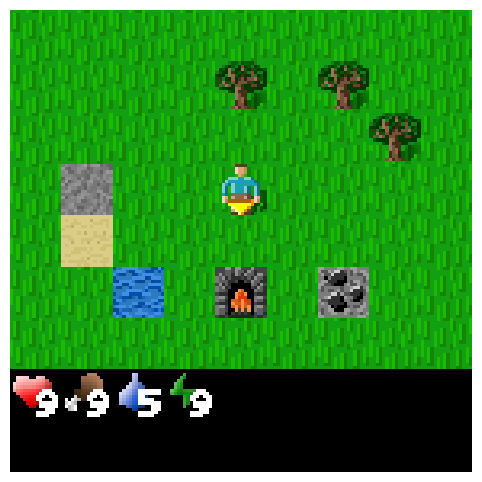

STYLE: baseline

SYSTEM:
 You are the high-level planner for a Craftax survival agent.
You may rely on the supplied game-mechanics catalog as authoritative knowledge of skill requirements, resource costs, and successful effects.
At each option boundary, rank only the supplied skills by how useful they are as the next requested skill from the current state.
The ranking is recomputed after every completed or failed skill.
Prioritize unmet prerequisites in execution order. Once a prerequisite is achieved, promote the next unmet objective step and demote redundant repetitions unless another repetition is necessary.
A separate affordance model checks whether each skill is executable, but state progress and recent outcomes must still affect usefulness.
A requirement named world.<resource>_reachable means the player can walk to that resource and interact with it within the skill horizon, searching only the area currently visible. The matching world.<resource>_steps value is the fewest steps t

In [4]:
preview_environment = chain_environment(CHAIN)
preview_state = preview_environment.reset(jax.random.PRNGKey(EVALUATION_SEED)).state
preview_pixels = render_state(
    preview_state,
    vlm_config.environment_name,
    block_pixel_size=vlm_config.block_pixel_size,
)
plt.figure(figsize=(8, 6))
plt.imshow(preview_pixels)
plt.axis("off")
plt.show()

# Both prompts are printed because the ablation measures the difference between
# them. BASELINE is the prompt that produced ungrounded_top = 0.745 and is kept
# byte for byte; AVAILABLE_FIRST hands the model the availability it was being
# asked to infer and makes it echo that list before the schema lets it choose.
preview_prompts = {}
for style in PlannerPromptStyle:
    preview_prompt = build_planner_prompt(
        preview_state,
        context=PlannerContext(
            objective=CHAIN.objective,
        ),
        candidate_skills=CHAIN.skills,
        style=style,
    )
    print("=" * 78)
    print(f"STYLE: {style.value}")
    preview_prompts[style.value] = (
        build_planner_system_prompt(style, CHAIN.skills),
        preview_prompt,
    )
    print("\nSYSTEM:\n", preview_prompts[style.value][0])
    print("\nUSER:\n", preview_prompt)

# Identifies the planner a saved closed loop was run with. The preview
# prompts stand in for the templates, so an edit to either style changes it.
PLANNER_FINGERPRINT = hashlib.sha256(
    json.dumps(
        {
            "config": dataclasses.asdict(vlm_config),
            "available_shuffle_seed": EVALUATION_SEED,
            "prompts": preview_prompts,
        },
        sort_keys=True,
        default=str,
    ).encode()
).hexdigest()[:16]
print("Planner fingerprint:", PLANNER_FINGERPRINT)

In [5]:
# Cheap grounding check: compare what the precondition knows against what is
# actually within reach. The precondition is true whenever a block exists
# anywhere on the 64x64 map, which is why it ranked unreachable skills first.
preview_context = PlannerContext(objective=CHAIN.objective)
preview_steps = skill_reachability_report(
    preview_state,
    DEFAULT_REACHABILITY,
    skill_ids=CHAIN.skills,
)
preview_graded = reachability_feasibility.score_all_feasibility(
    preview_state,
    preview_context,
    CHAIN.skills,
)
print(f"{'skill':22s} {'precondition':>12s} {'steps':>7s} {'graded':>8s}")
for skill_id in CHAIN.skills:
    steps = preview_steps[skill_id]
    print(
        f"{skill_id.value:22s} "
        f"{symbolic_feasibility(preview_state, preview_context, skill_id):12.2f} "
        f"{'-' if steps is None else steps:>7} "
        f"{preview_graded[skill_id]:8.2f}"
    )

skill                  precondition   steps   graded
collect_wood                   1.00       2     1.00
collect_stone                  0.00       3     0.00
drink_water                    1.00       4     1.00
place_table                    0.00       1     0.00
craft_wood_pickaxe             0.00       -     0.00
craft_wood_sword               0.00       -     0.00


## End-to-end VLM smoke test

This performs one real multimodal generation and verifies constrained decoding, complete-ranking validation, and symbolic grounding before the longer evaluations run.

In [6]:
backend = TransformersVLMBackend(vlm_config)
# The available skills are listed in a seeded order. Catalog order always puts
# collect_wood first, and the model picked it over an available collect_stone
# at the final boundary in every run; the seeded order scored at or above
# catalog order in all four runs that measured both (closed loop 19 against
# 13 of 64 in the last, paired p = 0.26), so it is the default and catalog
# order the ablation.
vlm_utility = VLMUtilityScorer(
    backend=backend,
    config=vlm_config,
    available_shuffle_seed=EVALUATION_SEED,
)
# Separate scorers, because the response cache is per scorer and different
# prompts must not share generations. One backend, so the model weights are
# loaded once; the constrained generator is cached per schema.
vlm_fixed_order_utility = VLMUtilityScorer(backend=backend, config=vlm_config)
vlm_baseline_utility = VLMUtilityScorer(
    backend=backend,
    config=vlm_config,
    prompt_style=PlannerPromptStyle.BASELINE,
)

if RUN_VLM_SMOKE_TEST:
    smoke_result = run_vlm_smoke_test(
        vlm_config,
        scorer=vlm_utility,
        seed=EVALUATION_SEED,
    )
    print(smoke_result.to_dict())

Loading weights: 100%|██████████| 625/625 [00:31<00:00, 19.92it/s]


{'model_id': 'Qwen/Qwen3-VL-2B-Instruct', 'elapsed_seconds': 45.25942780799994, 'ranking': ('collect_wood', 'drink_water', 'craft_wood_pickaxe', 'craft_wood_sword', 'collect_stone', 'place_table'), 'utility_selected_skill': 'collect_wood', 'grounded_selected_skill': 'collect_wood', 'grounded_feasibility': 1.0, 'progress_assessment': 'Player has water and trees, but no crafting table or pickaxe. Must collect wood first, then craft pickaxe, then use it to collect stone.', 'raw_response': '{ "progress_assessment": "Player has water and trees, but no crafting table or pickaxe. Must collect wood first, then craft pickaxe, then use it to collect stone.", "available_now": ["collect_wood", "drink_water"], "selected_skill": "collect_wood", "ranking": ["collect_wood", "drink_water", "craft_wood_pickaxe", "craft_wood_sword", "collect_stone", "place_table"] }'}


## Probe the skills, then fit two competence heads

The skill environment pays one sparse reward on success and terminates there, so the goal-conditioned critic estimates `E[gamma ** k] * P(success)`: in principle monotone in success probability, squashed by discounting. That was the hypothesis. The cell below tests it instead of assuming it, by probing every skill at every boundary from a copy of the boundary state, recording what the critic predicted, and fitting an isotonic map from critic value to success.

The measurement refuted it. Watch `auc` in the per-skill table: pooled it came out at 0.43 and per skill at roughly 0.5. The reason is in the training distribution - `local_navigation` always spawns a reachable target, so the critic never saw a state where its skill was impossible and learned to encode skill identity instead. An isotonic fit must be non-decreasing, but the cross-skill relation between value and success is decreasing, so the fit flattens to the base rate and the Can term becomes a near-constant multiplier. Rank utilities differ by 4x between adjacent positions; a factor that varies by 1.15x cannot reorder anything.

So the same labels feed a second head. `fit_affordance_competence_prior` tabulates success by `(skill, reachable, distance band)` - the three features the labels show carry signal - and shrinks each cell toward its parent so a thin cell inherits an estimate instead of reading 0 or 1. Samples whose symbolic precondition failed are dropped, because the precondition vetoes at scoring time anyway.

Both heads are fitted on `CALIBRATION_SEED` and scored on `CALIBRATION_EVAL_SEED`. The in-sample ECE of an isotonic fit is identically zero by construction, so a single-seed protocol reports a perfect number for a head that carries no information.

`unreachable_successes` is the other number worth watching: it counts skills the reachability predicate called unreachable that the executor completed anyway by walking out of the observation window. Every one is an episode a hard gate would have thrown away, which is why both the reachability term and the competence prior grade rather than veto.

The fits are saved so a later session can skip re-probing: `critic_affordance_scorer_from_checkpoint(checkpoint_path, calibration_path=run_dir(name) / "affordance_calibration.json")` for the retired ablation, `CompetencePrior.load(run_dir(name) / "competence_prior.json")` for the head in use.

Each executor gets its own probes and its own fits. The probe states are reached by the scripted oracle, not by the executor under test, so both executors are probed from identical boundary states on the held-out seed and their outcomes pair one for one: the cell after the fitted table compares the two executors with the planner taken out entirely. Randomized training still places a solvable target in every episode, so the critic is not expected to recover; it is re-measured because a recovery would be the result worth knowing.

In [7]:
for executor_name, path in EXECUTOR_CHECKPOINTS.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {executor_name} executor checkpoint: {path}")

# One load per executor, shared by its affordance scorer and its closed-loop
# executor, so the critic being measured belongs to the policy under test.
checkpoints = {
    executor_name: load_goal_conditioned_checkpoint(path)
    for executor_name, path in EXECUTOR_CHECKPOINTS.items()
}
executors = {
    executor_name: make_learned_skill_executor(checkpoint, deterministic=False)
    for executor_name, checkpoint in checkpoints.items()
}
for executor_name, executor in executors.items():
    missing = [skill for skill in CHAIN.skills if skill not in executor.skill_ids]
    if missing:
        raise ValueError(
            f"The {executor_name} executor was not trained on "
            f"{[skill.value for skill in missing]}, which {CHAIN.name} needs. "
            "Train a seven-skill executor in notebook 07 and select it."
        )
for executor_name, checkpoint in checkpoints.items():
    print(
        f"{executor_name}: scenario={checkpoint.config.skill_scenario} "
        f"skill_horizon={checkpoint.config.skill_horizon} "
        f"gamma={checkpoint.config.gamma} "
        f"skills={checkpoint.config.num_skills}"
    )


def print_calibration(report, competence_report):
    print("critic overall:", json.dumps(report["overall"], indent=2, default=float))
    print(
        "competence overall:",
        json.dumps(competence_report["overall"], indent=2, default=float),
    )
    print(
        f"base_rate={competence_report['base_rate']:.3f} "
        f"unreachable_rate={report['unreachable_rate']:.3f} "
        f"unreachable_successes={report['unreachable_successes']} "
        f"reachable_success_rate={report['reachable_success_rate']:.3f} "
        f"unreachable_success_rate={report['unreachable_success_rate']:.3f}"
    )
    # Two populations, each read against its own success rate. The critic is
    # scored on every probe; the prior only on probes whose precondition held,
    # because the precondition vetoes the rest at scoring time. Reading the
    # prior against the all-probe rate made a well-calibrated place_table
    # look like 0.98 predicted against 0.17 observed.
    print(f"\n{'':22s} {'critic, all probes':>30s} | {'prior, precondition held':>24s}")
    print(
        f"{'skill':22s} {'n':>4s} {'mean_value':>10s} {'auc':>6s} "
        f"{'success':>7s} | {'n':>4s} {'prior_p':>8s} {'success':>8s}"
    )
    for skill_name, metrics in report["per_skill"].items():
        prior_metrics = competence_report["per_skill"].get(skill_name, {})
        print(
            f"{skill_name:22s} {int(metrics['num_samples']):4d} "
            f"{metrics['mean_critic_value']:10.3f} {metrics['auc']:6.3f} "
            f"{metrics['success_rate']:7.3f} | "
            f"{int(prior_metrics.get('num_samples', 0)):4d} "
            f"{prior_metrics.get('mean_probability', float('nan')):8.3f} "
            f"{prior_metrics.get('success_rate', float('nan')):8.3f}"
        )


competence_priors = {}
competence_reports = {}
held_out_samples = {}
for executor_name, checkpoint in checkpoints.items():
    calibration_path = run_dir(executor_name) / (
        f"affordance_calibration{CHAIN_SUFFIX}.json"
    )
    prior_path = run_dir(executor_name) / f"competence_prior{CHAIN_SUFFIX}.json"
    if not RUN_AFFORDANCE_CALIBRATION:
        # The critic fit is still measured and saved whenever probing runs, so
        # its AUC is reproduced, but no planner uses it any more.
        competence_priors[executor_name] = (
            CompetencePrior.load(prior_path) if prior_path.exists() else None
        )
        continue

    uncalibrated_affordance = make_critic_affordance_scorer(checkpoint)
    started = time.perf_counter()
    fit_samples = collect_affordance_samples(
        uncalibrated_affordance,
        executors[executor_name],
        chain=CHAIN,
        num_episodes=NUM_CALIBRATION_EPISODES,
        seed=CALIBRATION_SEED,
        candidate_skills=CHAIN.skills,
        skill_horizon=SKILL_HORIZON,
    )
    held_out_samples[executor_name] = collect_affordance_samples(
        uncalibrated_affordance,
        executors[executor_name],
        chain=CHAIN,
        num_episodes=NUM_CALIBRATION_EPISODES,
        seed=CALIBRATION_EVAL_SEED,
        candidate_skills=CHAIN.skills,
        skill_horizon=SKILL_HORIZON,
    )
    probe_seconds = time.perf_counter() - started

    calibration = fit_affordance_calibration(fit_samples)
    calibration.save(calibration_path)
    competence_priors[executor_name] = fit_affordance_competence_prior(
        fit_samples,
        skills=CHAIN.skills,
    )
    competence_priors[executor_name].save(prior_path)

    report = evaluate_affordance_calibration(
        held_out_samples[executor_name],
        calibration,
    )
    competence_reports[executor_name] = evaluate_competence_prior(
        held_out_samples[executor_name],
        competence_priors[executor_name],
    )
    print(
        f"\n=== {executor_name} executor ===\n"
        f"fit_samples={len(fit_samples)} "
        f"held_out_samples={report['num_samples']} "
        f"held_out={report['held_out']} "
        f"seconds={probe_seconds:.1f}"
    )
    print_calibration(report, competence_reports[executor_name])

competence_prior = competence_priors[PRIMARY_EXECUTOR]
competence_report = competence_reports.get(PRIMARY_EXECUTOR)

baseline: scenario=local_navigation skill_horizon=32 gamma=0.95
candidate: scenario=randomized skill_horizon=64 gamma=0.95

=== baseline executor ===
fit_samples=432 held_out_samples=432 held_out=True seconds=140.8
critic overall: {
  "num_samples": 432.0,
  "base_rate": 0.30092592592592593,
  "auc": 0.3687722873153337,
  "raw_brier": 0.5012795961657981,
  "raw_ece": 0.4860221860861337,
  "calibrated_brier": 0.2190707082182166,
  "calibrated_ece": 0.04709496419927075
}
competence overall: {
  "num_samples": 192.0,
  "base_rate": 0.6770833333333334,
  "auc": 0.7377791563275434,
  "raw_brier": 0.2079368187670769,
  "raw_ece": 0.15985050976007412
}
base_rate=0.677 unreachable_rate=0.627 unreachable_successes=11 reachable_success_rate=0.739 unreachable_success_rate=0.041

                                   critic, all probes | prior, precondition held
skill                     n mean_value    auc success |    n  prior_p  success
collect_stone            72      0.574  0.783   0.111 |   12 

In [8]:
# The fitted table, cell by cell. `fit_support` is how many probes the cell was
# estimated from and `probability` is the shrunk estimate, so a small support
# next to a probability near its neighbours is shrinkage doing its job rather
# than evidence. `success_rate` is the held-out outcome on the same rows.
if competence_prior is None:
    print("No competence prior available; run the cell above or fit one.")
else:
    print(f"executor: {PRIMARY_EXECUTOR}")
    print(
        f"{'skill':22s} {'band':>18s} {'fit_n':>6s} {'p':>6s} "
        f"{'eval_n':>7s} {'success':>8s}"
    )
    rows = competence_report["cells"] if competence_report is not None else []
    for cell in rows:
        print(
            f"{cell['skill']:22s} {cell['label']:>18s} "
            f"{cell['fit_support']:6d} {cell['probability']:6.3f} "
            f"{cell['num_samples']:7d} {cell['success_rate']:8.3f}"
        )
    if not rows:
        print("(loaded from disk; re-run probing to score it on held-out states)")
    print("\ndistance bands:", competence_prior.distance_edges)
    print("floor:", competence_prior.floor)
    print("fitted base rate:", round(competence_prior.base_rate, 3))

executor: candidate
skill                                band  fit_n      p  eval_n  success
collect_wood                  unreachable     12  1.000      12    1.000
collect_wood                     steps<=2     21  1.000      17    1.000
collect_wood                  3<=steps<=6     36  1.000      43    1.000
collect_stone                 unreachable      2  1.000       1    1.000
collect_stone                    steps<=2      3  1.000       3    1.000
collect_stone                 3<=steps<=6      7  1.000       6    0.833
collect_stone                     steps>6      0  1.000       2    1.000
drink_water                   unreachable     10  1.000      18    1.000
drink_water                      steps<=2     10  1.000       5    1.000
drink_water                   3<=steps<=6     51  1.000      46    1.000
drink_water                       steps>6      1  1.000       3    1.000
place_table                      steps<=2     12  1.000      12    1.000
craft_wood_pickaxe             

In [9]:
# Both executors probed from the same oracle states on the held-out seed, so
# each probe pairs with its counterpart. This is the executor comparison with
# no planner in it: a gain here that the closed loop does not show is lost to
# the states the executor itself reaches.
def probe_key(sample):
    return (sample.episode, sample.boundary, sample.skill_id)


if {"baseline", "candidate"} <= held_out_samples.keys():
    probes = {
        executor_name: {probe_key(sample): sample for sample in samples}
        for executor_name, samples in held_out_samples.items()
    }
    shared = [key for key in probes["baseline"] if key in probes["candidate"]]
    groups = {
        "all": shared,
        "reachable": [key for key in shared if probes["baseline"][key].reachable],
        "unreachable": [key for key in shared if not probes["baseline"][key].reachable],
        **{
            skill_id.value: [key for key in shared if key[2] is skill_id]
            for skill_id in CHAIN.skills
        },
    }
    print(
        f"{'probes':22s} {'n':>4s} {'baseline':>8s} {'candidate':>9s} "
        f"{'base_only':>9s} {'cand_only':>9s} {'diff':>6s} {'p':>6s}"
    )
    for group, keys in groups.items():
        if not keys:
            continue
        reference = [probes["baseline"][key].succeeded for key in keys]
        candidate = [probes["candidate"][key].succeeded for key in keys]
        paired = paired_success_summary(reference, candidate)
        print(
            f"{group:22s} {len(keys):4d} {np.mean(reference):8.3f} "
            f"{np.mean(candidate):9.3f} {paired['reference_only']:9d} "
            f"{paired['candidate_only']:9d} {paired['difference']:+6.3f} "
            f"{paired['p_value']:6.3f}"
        )
else:
    print("Paired probes need probing to run with both executors.")

probes                    n baseline candidate base_only cand_only   diff      p
all                     432    0.301     0.442         1        62 +0.141  0.000
reachable               161    0.739     0.994         1        42 +0.255  0.000
unreachable             271    0.041     0.114         0        20 +0.074  0.000
collect_wood             72    0.611     1.000         0        28 +0.389  0.000
collect_stone            72    0.111     0.153         1         4 +0.042  0.375
drink_water              72    0.583     1.000         0        30 +0.417  0.000
place_table              72    0.167     0.167         0         0 +0.000  1.000
craft_wood_pickaxe       72    0.167     0.167         0         0 +0.000  1.000
craft_wood_sword         72    0.167     0.167         0         0 +0.000  1.000


## Controlled-prefix planner ablation

The same randomized states are used for every planner, and because the scripted oracle ignores the planner they are collected once, as a `PrefixTrajectory`, and every condition is scored on it. Episodes advance in lockstep, so one batched generation covers every episode's decision at a boundary, and the response cache means conditions sharing a scorer share generations. The ladder therefore costs roughly one batched pass per boundary per distinct prompt - three prompts, three passes - rather than one generation per episode per boundary.

The ladder has two axes. The first is where grounding comes from: the `available_first` prompt hands the model the availability list, the `baseline` prompt does not and leaves grounding to the Can term. The closed loop settled it for the Can term (62 against 50 of 64, p = 0.002), so `baseline_plus_reachability` is the main condition and the `available_first` rows are ablations. The second axis, which Can term, is only measured under `baseline`, because under `available_first` the model's top choice is already reachable at 96% of boundaries and every Can term scored identically.

| condition | prompt | Can | isolates |
| --- | --- | --- | --- |
| `scripted_oracle` | private reference sequence | reachability | reference |
| `feasibility_only` | uniform | reachability | lower bound |
| `baseline_plus_reachability` | `baseline` | reachability | **main condition**: grounding from the Can term |
| `baseline_plus_reachability_skip_held` | `baseline` | reachability, crafts of a held tool vetoed | the second-pickaxe waste |
| `baseline_plus_competence_prior` | `baseline` | measured `(skill, reachable, steps)` success rates | measured competence against reachability |
| `baseline_prompt_only` | `baseline` | none | the ungrounded VLM |
| `vlm_plus_reachability` | `available_first`, seeded order | reachability | grounding in the prompt; refuted as the main condition, 50 against 62 of 64 |
| `vlm_fixed_order` | `available_first`, catalog order | reachability | position bias |
| `vlm_only` | `available_first`, seeded order | none | whether Can adds anything once the prompt grounds |

Names changed with the restructure: `vlm_plus_reachability` was `vlm_shuffled_available`, `vlm_fixed_order` was `vlm_plus_reachability`, and `baseline_plus_reachability` was `vlm_baseline_prompt`. Three conditions were retired from runs, with the code and their numbers kept: `vlm_plus_symbolic` (preconditions hold almost everywhere on the map, and it matched reachability exactly), `vlm_plus_critic_affordance` (held-out AUC 0.369 and an identical closed loop at 2.8 times the cost), and `vlm_plus_competence_prior` under `available_first` (identical to reachability; it moved to `baseline`).

Rankings that repeat a skill are repaired at parse time - first occurrences kept, omitted skills appended - because the schema fixes the ranking's length but not that its entries are distinct, and the available-first model filled the slots by cycling the available skills. A `selected_skill` that disagrees with the ranking's head is moved to the top. `repaired` is the share of boundaries that needed either and `strict` is the accuracy strict parsing would have given, read from the same generations.

Three metrics matter beyond accuracy. `ungrounded_top` is the share of boundaries where a reachable skill existed and the VLM still ranked an unreachable one first - the dominant error under `baseline`, and identical across conditions that share a utility scorer because it measures the VLM alone. `rescued` is how often the Can term then recovered an accepted skill. `grounded` is how often the chosen skill was usable from that exact state.

On the wood-to-stone chain, three of the 48 boundaries in the `full` preset have an unreachable reference skill, so a grounded planner can accept at most 45. A condition above that is being credited for walking off to search, which is why `baseline_prompt_only` can look better on `accepted` than it is; read it together with `grounded`.

In [10]:
def chain_planner(**scorers):
    # Every condition chooses from the chain's catalog, which is also the one
    # its prompt describes.
    return SayCanPlanner(candidate_skills=CHAIN.skills, **scorers)


prefix_planners = {
    "scripted_oracle": chain_planner(
        utility_scorer=SequentialUtilityScorer(CHAIN.reference_skills),
    ),
    "feasibility_only": chain_planner(utility_scorer=constant_utility),
    # Grounding in the Can term, which is the main condition. These four share
    # one scorer, so the ladder pays for the baseline prompt once.
    "baseline_prompt_only": chain_planner(
        utility_scorer=vlm_baseline_utility,
        feasibility_scorer=constant_feasibility,
    ),
    MAIN_CONDITION: chain_planner(
        utility_scorer=vlm_baseline_utility,
        feasibility_scorer=reachability_feasibility,
    ),
    # The main condition with a craft vetoed once its result is held. The veto
    # reads only the skills' declared effects, never the chain.
    "baseline_plus_reachability_skip_held": chain_planner(
        utility_scorer=vlm_baseline_utility,
        feasibility_scorer=SkipHeldCraftFeasibility(reachability_feasibility),
    ),
    # Grounding in the prompt: the ablation the main condition replaced.
    "vlm_plus_reachability": chain_planner(
        utility_scorer=vlm_utility,
        feasibility_scorer=reachability_feasibility,
    ),
    # Order of the available list changed, everything else held fixed.
    "vlm_fixed_order": chain_planner(
        utility_scorer=vlm_fixed_order_utility,
        feasibility_scorer=reachability_feasibility,
    ),
    "vlm_only": chain_planner(
        utility_scorer=vlm_utility,
        feasibility_scorer=constant_feasibility,
    ),
}
# The primary executor's prior. The closed loop plans for each executor with
# its own.
if competence_prior is not None:
    prefix_planners["baseline_plus_competence_prior"] = chain_planner(
        utility_scorer=vlm_baseline_utility,
        feasibility_scorer=competence_prior,
    )

prefix_results = {}
if RUN_PREFIX:
    # The oracle ignores the planner, so its rollout is shared by every
    # condition.
    started = time.perf_counter()
    prefix_trajectory = collect_prefix_trajectory(
        chain=CHAIN,
        num_episodes=NUM_PREFIX_EPISODES,
        seed=EVALUATION_SEED,
        skill_horizon=SKILL_HORIZON,
    )
    print(
        f"oracle trajectory: {sum(map(len, prefix_trajectory.boundaries))} "
        f"boundaries, {prefix_trajectory.oracle_progress_failures} failures, "
        f"seconds={time.perf_counter() - started:.2f}"
    )

    for name, planner in prefix_planners.items():
        started = time.perf_counter()
        result = evaluate_planner_prefixes(
            planner,
            chain=CHAIN,
            num_episodes=NUM_PREFIX_EPISODES,
            seed=EVALUATION_SEED,
            skill_horizon=SKILL_HORIZON,
            trajectory=prefix_trajectory,
        )
        prefix_results[name] = result
        print(
            f"{name:36s} accepted={result['accepted_next_skill_accuracy']:.3f} "
            f"strict={result['strict_accepted_next_skill_accuracy']:.3f} "
            f"parse_valid={result['valid_utility_response_rate']:.3f} "
            f"repaired={result['repaired_utility_response_rate']:.3f} "
            f"valid={result['valid_selection_rate']:.3f} "
            f"grounded={result['grounded_selection_rate']:.3f} "
            f"ungrounded_top={result['ungrounded_top_choice_rate']:.3f} "
            f"rescued={result['feasibility_rescue_rate']:.3f} "
            f"reachable_skills={result['mean_feasible_skills']:.2f} "
            f"seconds={time.perf_counter() - started:.2f}"
        )
        if result["invalid_utility_errors"]:
            print(f"  invalid={result['invalid_utility_errors']}")

    # Accepted accuracy per boundary. The baseline rows show where each Can
    # term rescues the ungrounded prompt; the last two differ in list order
    # alone, so a gap between them at the final boundary is position bias.
    BOUNDARY_CONDITIONS = tuple(
        name
        for name in (
            "baseline_prompt_only",
            MAIN_CONDITION,
            "baseline_plus_reachability_skip_held",
            "baseline_plus_competence_prior",
            "vlm_plus_reachability",
            "vlm_fixed_order",
        )
        if name in prefix_results
    )
    num_boundaries = len(prefix_trajectory.boundaries)
    print(
        f"\n{'condition':36s} "
        + " ".join(f"{'b' + str(boundary):>5s}" for boundary in range(num_boundaries))
    )
    for name in BOUNDARY_CONDITIONS:
        traces = prefix_results[name]["traces"]
        cells = []
        for boundary in range(num_boundaries):
            matched = [trace.matched for trace in traces if trace.boundary == boundary]
            cells.append(f"{sum(matched)}/{len(matched)}".rjust(5))
        print(f"{name:36s} " + " ".join(cells))
else:
    print("Prefix ladder skipped: it does not depend on the executor.")


oracle trajectory: 48 boundaries, 0 failures, seconds=20.66
scripted_oracle             accepted=1.000 strict=1.000 parse_valid=1.000 repaired=0.000 valid=1.000 grounded=0.938 ungrounded_top=0.000 rescued=0.000 reachable_skills=2.33 seconds=4.29
feasibility_only            accepted=0.729 strict=0.729 parse_valid=1.000 repaired=0.000 valid=1.000 grounded=1.000 ungrounded_top=0.000 rescued=0.000 reachable_skills=2.33 seconds=4.29
vlm_plus_reachability       accepted=0.938 strict=0.917 parse_valid=1.000 repaired=0.021 valid=1.000 grounded=1.000 ungrounded_top=0.042 rescued=0.042 reachable_skills=2.33 seconds=34.52
vlm_fixed_order             accepted=0.896 strict=0.750 parse_valid=1.000 repaired=0.146 valid=1.000 grounded=1.000 ungrounded_top=0.042 rescued=0.042 reachable_skills=2.33 seconds=34.47
vlm_only                    accepted=0.896 strict=0.875 parse_valid=1.000 repaired=0.021 valid=1.000 grounded=0.958 ungrounded_top=0.042 rescued=0.000 reachable_skills=2.33 seconds=5.92
baseline

In [11]:
# The main condition. Only available_first responses carry the available_now
# echo read below, so set this to vlm_plus_reachability to compare the echo
# with the true reachable set.
INSPECT_CONDITION = MAIN_CONDITION

# Prints nothing when the prefix ladder was skipped.
for trace in prefix_results.get(INSPECT_CONDITION, {"traces": []})["traces"]:
    selected = trace.selected_skill.value if trace.selected_skill else "none"
    accepted = ",".join(skill.value for skill in trace.accepted_skills)
    reachable = ",".join(skill.value for skill in trace.feasible_skills) or "none"
    ranking = " > ".join(skill.value for skill in trace.utility_ranking)
    print(
        f"episode={trace.episode} boundary={trace.boundary} "
        f"reference={trace.reference_skill.value:20s} selected={selected:20s} "
        f"accepted=[{accepted}] matched={trace.matched} "
        f"parse_valid={trace.utility_valid} repaired={trace.utility_repaired} "
        f"feasibility={trace.selected_feasibility:.2f}"
    )
    print(
        f"  reachable=[{reachable}] "
        f"top_feasible={trace.utility_top_feasible} "
        f"selected_feasible={trace.selected_feasible}"
    )
    if trace.utility_raw_response is not None:
        print(f"  ranking={ranking}")
        # Under the available_first prompt the model must echo the availability
        # list before the schema lets it choose. Comparing that echo against
        # the true reachable set separates two different failures: a wrong
        # echo is perception, a correct echo followed by an unavailable choice
        # is instruction following.
        try:
            claimed = json.loads(trace.utility_raw_response).get("available_now")
        except (json.JSONDecodeError, AttributeError):
            claimed = None
        if claimed is not None:
            truth = sorted(skill.value for skill in trace.feasible_skills)
            print(
                f"  claimed_available={sorted(claimed)} "
                f"matches_truth={sorted(claimed) == truth}"
            )
        print(f"  raw={trace.utility_raw_response}")
    if trace.utility_error is not None:
        print(f"  error={trace.utility_error}")

episode=0 boundary=0 reference=collect_wood         selected=collect_wood         accepted=[collect_wood] matched=True parse_valid=True repaired=False feasibility=1.00
  reachable=[collect_wood,drink_water] top_feasible=True selected_feasible=True
  ranking=collect_wood > drink_water > craft_wood_pickaxe > craft_wood_sword > collect_stone > place_table
  claimed_available=['collect_wood', 'drink_water'] matches_truth=True
  raw={ "progress_assessment": "Player has water and trees, but no crafting table or pickaxe. Must collect wood first, then craft pickaxe, then use it to collect stone.", "available_now": ["collect_wood", "drink_water"], "selected_skill": "collect_wood", "ranking": ["collect_wood", "drink_water", "craft_wood_pickaxe", "craft_wood_sword", "collect_stone", "place_table"] }
episode=0 boundary=1 reference=collect_wood         selected=collect_wood         accepted=[collect_wood] matched=True parse_valid=True repaired=False feasibility=1.00
  reachable=[collect_wood,drink_

## Closed-loop planner/executor ablation

Episodes advance in lockstep by decision index, like the prefix ladder: each decision depends only on its own episode's history, so every running episode is planned in one batched generation and its skills execute together in one compiled loop on device. Each episode keeps its own key, so the results equal running the episodes one by one. With 16 episodes the standard error on a success rate near 0.3 is about 0.11, too wide to separate conditions, so `full` runs 64. An invalid planner response ends its episode, and `planner_errors` says which validation failed. Each executor is the one loaded for calibration above, run stochastically, and is planned for with its own competence prior.

`scripted_collect_first` runs only here. It is the oracle with all the chain's wood collected before the table is placed, which scored 0.609 against 0.250 for the default order with the baseline executor in the last run, so it is the stronger fixed plan for a VLM to be measured against. It has no prefix-ladder row because the prefix states follow the default order.

Each chain gets a decision limit of twice its reference plan: 12 for the six-skill wood-to-stone chain, as before, and 16 for the eight-skill stone-pickaxe chain. Its world holds four trees, one per wood the chain needs, because a mined tree is gone.

Every condition runs on `EVALUATION_SEED`, so episode `i` starts from the same world in each, and the paired table below compares conditions episode by episode with an exact McNemar test. That removes the variance between worlds that an unpaired comparison of two rates carries: the last run's best and worst VLM conditions, 19 and 14 of 64, were Fisher p = 0.42 apart. The pairing holds the starting world, not the executor's samples once the plans diverge, so it is a lower bound on what pairing can buy.

With a candidate executor every condition runs twice, once per executor, on the same worlds, and the executor table pairs them condition by condition. The criterion notebook 07 set is the plan-order gap: if the candidate closes it, `scripted_oracle` gains the most and `scripted_collect_first` the least. Each executor's results are saved beside its checkpoint, every decision's trace included, and the VLM scorers are shared, so the first decision of every episode, which both executors face from the same state, is generated once.

In [12]:
def closed_loop_planners_for(prior):
    planners = {
        "scripted_oracle": prefix_planners["scripted_oracle"],
        "scripted_collect_first": chain_planner(
            utility_scorer=SequentialUtilityScorer(COLLECT_FIRST_PLANS[CHAIN.name]),
        ),
        **{
            name: planner
            for name, planner in prefix_planners.items()
            if name != "baseline_plus_competence_prior"
        },
    }
    if prior is not None:
        planners["baseline_plus_competence_prior"] = chain_planner(
            utility_scorer=vlm_baseline_utility,
            feasibility_scorer=prior,
        )
    if CLOSED_LOOP_CONDITIONS is None:
        return planners
    return {name: planners[name] for name in CLOSED_LOOP_CONDITIONS if name in planners}


# The sequencing diagnosis below only reads these conditions, so only their
# raw VLM responses -- the bulk of a saved closed loop -- are kept. The rest
# of each trace (requested skill, outcome, accepted set, scores) stays for
# every condition; only the free-text response is dropped.
SEQUENCING_CONDITIONS = (
    MAIN_CONDITION,
    "baseline_plus_reachability_skip_held",
    "vlm_plus_reachability",
)


def chain_summary(result, name):
    # The whole result, with every episode's serialized trace, so the
    # sequencing diagnosis can read a saved run. The pairing reads
    # episode_successes rather than the episodes.
    summary = json_ready_chain_result(result)
    summary["episode_successes"] = [
        bool(episode.succeeded) for episode in result["episodes"]
    ]
    if name not in SEQUENCING_CONDITIONS:
        for episode in summary["episodes"]:
            episode["planner_raw_response"] = None
            for step in episode["trace"]:
                step["planner_raw_response"] = None
    return summary


def closed_loop_path(executor_name):
    return run_dir(executor_name) / (
        f"closed_loop{CHAIN_SUFFIX}_seed{EVALUATION_SEED}_"
        f"n{NUM_CLOSED_LOOP_EPISODES}.json"
    )


def load_closed_loop(executor_name):
    path = closed_loop_path(executor_name)
    if not (REUSE_SAVED_CLOSED_LOOPS and path.is_file()):
        return {}
    saved = json.loads(path.read_text())
    if (
        saved["planner_fingerprint"] != PLANNER_FINGERPRINT
        or saved["skill_horizon"] != SKILL_HORIZON
    ):
        print(f"{executor_name}: saved closed loop is for another planner; rerunning")
        return {}
    # A condition saved before the traces were kept cannot be diagnosed, so it
    # is rerun; the rest are reused as they are.
    conditions = {}
    for name, result in saved["conditions"].items():
        if "episodes" in result:
            conditions[name] = result
        else:
            print(f"{executor_name}: saved {name} has no traces; rerunning")
    return conditions


# Each pair is (reference, candidate) and isolates one choice from the ladder.
PAIRED_COMPARISONS = (
    ("scripted_oracle", "scripted_collect_first", "plan order"),
    ("scripted_collect_first", MAIN_CONDITION, "VLM against the best fixed plan"),
    ("feasibility_only", MAIN_CONDITION, "VLM against no utility"),
    ("baseline_prompt_only", MAIN_CONDITION, "Can as the grounding"),
    (MAIN_CONDITION, "baseline_plus_reachability_skip_held", "held-craft veto"),
    (MAIN_CONDITION, "baseline_plus_competence_prior", "which Can"),
    (MAIN_CONDITION, "vlm_plus_reachability", "prompt against Can grounding"),
    ("vlm_fixed_order", "vlm_plus_reachability", "position bias"),
    ("vlm_only", "vlm_plus_reachability", "Can under the grounded prompt"),
)

if RUN_CLOSED_LOOP:
    closed_loop_results = {}
    for executor_name, executor in executors.items():
        print(f"\n=== {executor_name} executor ===")
        results = load_closed_loop(executor_name)
        planners = closed_loop_planners_for(competence_priors[executor_name])
        for name, planner in planners.items():
            if name in results:
                seconds = "saved"
            else:
                started = time.perf_counter()
                results[name] = chain_summary(
                    evaluate_skill_chain(
                        executor,
                        planner=planner,
                        chain=CHAIN,
                        num_episodes=NUM_CLOSED_LOOP_EPISODES,
                        seed=EVALUATION_SEED,
                        skill_horizon=SKILL_HORIZON,
                    ),
                    name,
                )
                seconds = f"{time.perf_counter() - started:.2f}"
            result = results[name]
            print(
                f"{name:36s} success={result['success_rate']:.3f} "
                f"skills={result['mean_completed_skills']:.2f} "
                f"steps={result['mean_environment_steps']:.1f} "
                f"seconds={seconds} "
                f"terminations={result['termination_counts']}"
            )
            print(
                f"  final_failed_skills={result['final_failed_skill_counts']} "
                f"outcomes={result['final_failure_outcome_counts']}"
            )
            if result["planner_error_counts"]:
                print(f"  planner_errors={result['planner_error_counts']}")
        closed_loop_results[executor_name] = {name: results[name] for name in planners}
        closed_loop_path(executor_name).write_text(
            json.dumps(
                {
                    "planner_fingerprint": PLANNER_FINGERPRINT,
                    "skill_horizon": SKILL_HORIZON,
                    "conditions": results,
                },
                indent=2,
                default=float,
            )
        )

    # Discordant episodes are the evidence: ref_only succeeded under the
    # reference alone, cand_only under the candidate alone.
    for executor_name, results in closed_loop_results.items():
        print(
            f"\n{executor_name + ' executor':36s} {'candidate':36s} {'both':>4s} "
            f"{'ref_only':>8s} {'cand_only':>9s} {'diff':>6s} {'p':>6s}  isolates"
        )
        for reference, candidate, isolates in PAIRED_COMPARISONS:
            if reference not in results or candidate not in results:
                continue
            comparison = compare_paired_successes(
                results[reference],
                results[candidate],
            )
            print(
                f"{reference:36s} {candidate:36s} {comparison['both']:4d} "
                f"{comparison['reference_only']:8d} "
                f"{comparison['candidate_only']:9d} "
                f"{comparison['difference']:+6.3f} {comparison['p_value']:6.3f}  "
                f"{isolates}"
            )

    # Old executor against new, condition by condition on the same worlds. The
    # worlds pair but the executors' samples do not, so this is a lower bound
    # on what pairing can buy.
    if {"baseline", "candidate"} <= closed_loop_results.keys():
        print(
            f"\n{'condition':36s} {'baseline':>8s} {'candidate':>9s} {'both':>4s} "
            f"{'base_only':>9s} {'cand_only':>9s} {'diff':>6s} {'p':>6s}"
        )
        for name, result in closed_loop_results["candidate"].items():
            if name not in closed_loop_results["baseline"]:
                continue
            reference = closed_loop_results["baseline"][name]
            comparison = compare_paired_successes(reference, result)
            print(
                f"{name:36s} {reference['success_rate']:8.3f} "
                f"{result['success_rate']:9.3f} {comparison['both']:4d} "
                f"{comparison['reference_only']:9d} "
                f"{comparison['candidate_only']:9d} "
                f"{comparison['difference']:+6.3f} {comparison['p_value']:6.3f}"
            )

    print()
    for executor_name, results in closed_loop_results.items():
        if {"scripted_oracle", "scripted_collect_first"} <= results.keys():
            default = results["scripted_oracle"]["success_rate"]
            collect_first = results["scripted_collect_first"]["success_rate"]
            print(
                f"{executor_name}: plan-order gap {collect_first - default:+.3f} "
                f"(default {default:.3f}, collect-first {collect_first:.3f})"
            )


=== baseline executor ===
scripted_oracle                 success=0.250 skills=3.89 steps=131.3 seconds=63.24 terminations={'success': 16, 'no_viable_skill': 0, 'failure_limit': 48, 'decision_limit': 0, 'invalid_planner_output': 0}
  final_failed_skills={'collect_wood': 41, 'craft_wood_pickaxe': 3, 'collect_stone': 4} outcomes={'timeout': 48}
scripted_collect_first          success=0.609 skills=5.14 steps=96.9 seconds=45.49 terminations={'success': 39, 'no_viable_skill': 2, 'failure_limit': 23, 'decision_limit': 0, 'invalid_planner_output': 0}
  final_failed_skills={'collect_stone': 15, 'collect_wood': 10} outcomes={'timeout': 24, 'precondition_lost': 1}
feasibility_only                success=0.172 skills=8.34 steps=165.0 seconds=58.01 terminations={'success': 11, 'no_viable_skill': 2, 'failure_limit': 18, 'decision_limit': 33, 'invalid_planner_output': 0}
  final_failed_skills={'collect_wood': 34, 'collect_stone': 2, 'place_table': 13, 'drink_water': 3} outcomes={'timeout': 50, 'pre

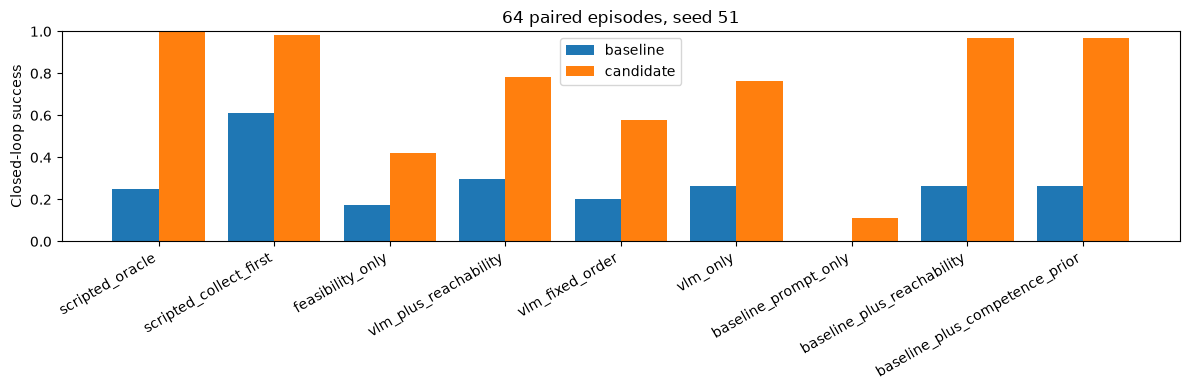

In [13]:
if RUN_CLOSED_LOOP:
    conditions = list(closed_loop_results[PRIMARY_EXECUTOR])
    positions = np.arange(len(conditions))
    width = 0.8 / len(closed_loop_results)
    plt.figure(figsize=(12, 4))
    for index, (executor_name, results) in enumerate(closed_loop_results.items()):
        offset = (index - (len(closed_loop_results) - 1) / 2) * width
        plt.bar(
            positions + offset,
            [results.get(name, {}).get("success_rate", np.nan) for name in conditions],
            width=width,
            label=executor_name,
        )
    plt.xticks(positions, conditions, rotation=30, ha="right")
    plt.ylabel("Closed-loop success")
    plt.ylim(0.0, 1.0)
    plt.title(f"{NUM_CLOSED_LOOP_EPISODES} paired episodes, seed {EVALUATION_SEED}")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Sequencing diagnosis

The run that set the main condition: the candidate executor finished every skill `vlm_plus_reachability` asked of it, yet 14 of its 64 episodes still ended at the 12-decision limit, and `baseline_plus_reachability` solved 13 of those 14 worlds. 162 of the 163 off-objective decisions were `say_led`, so the gap was the `available_first` prompt's. Under `baseline_plus_reachability` the waste left was a second wood pickaxe (23 decisions) and extra wood (25), which is what `baseline_plus_reachability_skip_held` targets: its pickaxe row should show no off-objective requests. This section reads the primary executor's saved traces for the main condition, the veto and the refuted prompt, and prints each failed episode beside the same world under the main condition.

Each decision is judged against the skills the objective accepted from the state it was made in: the chain's `valid_next_skills`, the set the prefix ladder calls `accepted`. A table costs two wood, the wood pickaxe one and the stone pickaxe one wood and one stone, so that set is exact - wood beyond what the chain needs, a second table, a drink or a sword never progress. A decision is `progress` when it asked for an accepted skill and the executor finished it, `off_obj` when the skill finished but was not accepted, and `failed` when the executor did not finish it.

The attribution columns split each choice by what the Say term ranked first, read from the planner's choice alone rather than the executor's outcome. `say_led`: the VLM ranked an unaccepted skill first and the chosen skill was unaccepted too, so the waste is the prompt's. `can_misled`: the VLM ranked an accepted skill first and the Can term moved the choice off it. `can_rescued` is the reverse. In the sequences `*` marks an off-objective request, `!outcome` a failed one, and `(skill)` the VLM's first choice wherever the Can term chose something else.

In [14]:
# Where each condition's decisions went, read from the saved traces. A saved
# run from before the traces were kept is rerun by the closed-loop cell.
# SEQUENCING_CONDITIONS is set above, where it also controls which raw VLM
# responses a closed loop keeps when it is saved.
traced = (
    {
        name: closed_loop_results[PRIMARY_EXECUTOR][name]["episodes"]
        for name in SEQUENCING_CONDITIONS
        if "episodes" in closed_loop_results[PRIMARY_EXECUTOR].get(name, {})
    }
    if RUN_CLOSED_LOOP
    else {}
)
sequencing = {}
if not traced:
    print("The sequencing diagnosis needs closed-loop traces; run the closed loop.")
else:
    print(f"executor: {PRIMARY_EXECUTOR}")
    print(
        f"{'condition':36s} {'subset':6s} {'n':>3s} {'decisions':>9s} "
        f"{'progress':>8s} {'off_obj':>7s} {'failed':>6s} | {'say_led':>7s} "
        f"{'can_misled':>10s} {'can_rescued':>11s}  terminations"
    )
    for name, episodes in traced.items():
        subsets = {
            "all": episodes,
            "failed": [episode for episode in episodes if not episode["succeeded"]],
        }
        sequencing[name] = {
            subset: sequencing_summary(group) for subset, group in subsets.items()
        }
        for subset, summary in sequencing[name].items():
            if not summary["num_episodes"]:
                continue
            kinds = summary["decision_kinds"]
            attributions = summary["attributions"]
            print(
                f"{name:36s} {subset:6s} {summary['num_episodes']:3d} "
                f"{summary['mean_decisions']:9.2f} {kinds['progress']:8d} "
                f"{kinds['off_objective']:7d} {kinds['failed']:6d} | "
                f"{attributions['say_led']:7d} {attributions['can_misled']:10d} "
                f"{attributions['can_rescued']:11d}  {summary['termination_counts']}"
            )

    # Requests per skill over every episode. `rep` counts a request of the skill
    # asked for at the decision just before.
    for name in traced:
        print(
            f"\n{name}\n{'skill':22s} {'req':>5s} {'prog':>5s} {'off':>5s} "
            f"{'fail':>5s} {'rep':>5s}"
        )
        for skill_id in CHAIN.skills:
            row = sequencing[name]["all"]["per_skill"][skill_id.value]
            print(
                f"{skill_id.value:22s} {row['requests']:5d} {row['progress']:5d} "
                f"{row['off_objective']:5d} {row['failed']:5d} {row['repeats']:5d}"
            )

    # The commonest off-objective choices, each with the VLM's own account of
    # progress at the first decision that made it.
    for name, episodes in traced.items():
        patterns = off_objective_choices(episodes)
        total = sum(len(steps) for steps in patterns.values())
        print(f"\n{name}: {total} off-objective choices")
        for (accepted, say_top, chosen), steps in list(patterns.items())[:6]:
            print(
                f"  {len(steps):3d}  accepted=[{','.join(accepted)}] "
                f"say_top={say_top} chosen={chosen}"
            )
            example = next(filter(None, map(planner_assessment, steps)), None)
            if example is not None:
                print(f"       e.g. {example[:150]!r}")

executor: candidate
condition                   subset   n decisions progress off_obj failed | say_led can_misled can_rescued  terminations
vlm_plus_reachability       all     64      8.28      367     163      0 |     162          1          16  {'success': 50, 'decision_limit': 14}
vlm_plus_reachability       failed  14     12.00       67     101      0 |     100          1           5  {'decision_limit': 14}
baseline_plus_reachability  all     64      7.25      382      82      0 |      78          4         257  {'success': 62, 'decision_limit': 2}
baseline_plus_reachability  failed   2     12.00       10      14      0 |      14          0           8  {'decision_limit': 2}

                               vlm_plus_reachability |    baseline_plus_reachability
skill                    req  prog   off  fail   rep |   req  prog   off  fail   rep
collect_wood             282   192    90     0    55 |   231   192    39     0    26
collect_stone             50    50     0     0     0 |  

In [15]:
# Every failed episode of each traced condition on one line, beside the same
# world under the main condition: every condition runs on EVALUATION_SEED, so
# episode i starts from the same world in each. The last line is the first
# decision that did not progress, with the VLM's full ranking.
def abbreviate(skill):
    return SKILL_ABBREVIATIONS.get(skill, skill)


main_episodes = traced.get(MAIN_CONDITION)
for name, episodes in traced.items():
    beside_main = main_episodes is not None and name != MAIN_CONDITION
    failed = [index for index, episode in enumerate(episodes) if not episode["succeeded"]]
    solved = (
        f", of which {MAIN_CONDITION} solved "
        f"{sum(main_episodes[index]['succeeded'] for index in failed)}"
        if beside_main
        else ""
    )
    print(f"\n{name}: {len(failed)} failed{solved}")
    for index in failed:
        episode = episodes[index]
        print(
            f"ep{index:3d} this {episode['termination']:15s} "
            f"d={episode['decisions']:2d}  {episode_sequence(episode)}"
        )
        if beside_main:
            reference = main_episodes[index]
            print(
                f"      main {reference['termination']:15s} "
                f"d={reference['decisions']:2d}  {episode_sequence(reference)}"
            )
        # UNKNOWN steps have no accepted set to judge, so they are not
        # waste; every chain here defines one, but skip them if it did not.
        waste = next(
            (
                step
                for step in episode["trace"]
                if decision_kind(step)
                in (DecisionKind.OFF_OBJECTIVE, DecisionKind.FAILED)
            ),
            None,
        )
        if waste is not None:
            accepted = ",".join(map(abbreviate, waste["accepted_skills"]))
            ranking = ">".join(map(abbreviate, waste["planner_ranking"])) or "-"
            assessment = planner_assessment(waste) or ""
            print(
                f"      first waste d{waste['decision_index']} "
                f"{decision_kind(waste).value}: accepted=[{accepted}] "
                f"ranking={ranking} {assessment[:110]!r}"
            )


failed under vlm_plus_reachability: 14, of which baseline_plus_reachability solved 13
ep  5 vlm  decision_limit  d=12  wood wood wood wood* wood* wood* table pickaxe pickaxe* pickaxe* pickaxe* wood*
      base success         d= 7  wood(pickaxe) water*(pickaxe) wood(pickaxe) table(pickaxe) wood(pickaxe) pickaxe stone
      first waste d3 off_objective: accepted=[table] ranking=wood>water>table>pickaxe>sword>stone "Player has 3 wood, can collect more. Needs to craft pickaxe, then use it to collect stone. Can't craft yet due"
ep  9 vlm  decision_limit  d=12  wood wood table water* water* water* water* wood(pickaxe) wood* wood* wood* table*(pickaxe)
      base success         d=11  wood(pickaxe) wood(pickaxe) table(pickaxe) wood(pickaxe) wood*(pickaxe) wood*(pickaxe) wood*(pickaxe) pickaxe pickaxe* wood* stone
      first waste d3 off_objective: accepted=[wood] ranking=water>wood>stone>pickaxe>sword>table 'Player has collected wood and placed a crafting table. Needs to drink water to proc

## Interpretation

- Low accepted-skill accuracy with valid JSON is a planner reasoning or visual-grounding failure.
- Invalid utility responses are reported separately from states with no viable skill.
- `ungrounded_top` quantifies the VLM's grounding error on its own. It must be identical across conditions that share a utility scorer, because no Can term can change what the VLM ranked first; only `grounded` and `accepted` should move. The gap between the `available_first` and `baseline` rows is the whole prompt result.
- `baseline_prompt_only` to `baseline_plus_reachability` measures how much of the grounding the Can term recovers on its own. `baseline_plus_reachability` to `baseline_plus_competence_prior` measures how much more comes from knowing what this executor can finish, read from measured success rates instead of from a value function that was never trained to answer the question.
- `baseline_plus_reachability` to `baseline_plus_reachability_skip_held` isolates the held-craft veto. It can only remove decisions, never change one where no tool is held, so its discordant episodes should all favour the veto; any that do not mean the decision a vetoed craft would have taken was itself the useful one. It is adopted as the main condition only if it holds on seed 202 as well.
- `vlm_only` to `vlm_plus_reachability` should be near zero. A Can term only helps when the VLM's top choice is unreachable, and the `available_first` prompt makes that rare.
- Watch `termination_counts` for `no_viable_skill` in the closed loop. Both the reachability term and the competence prior grade rather than veto - the prior has a floor precisely so that a measured 3% success rate stays selectable - because walking toward a distant resource must remain available; a hard gate here turned four-episode scripted chains from 1.0 down to 0.5 success.
- Good prefix accuracy but poor closed-loop success points to executor recovery or planner adaptation after failures.
- The available-first prompt took `ungrounded_top` from 0.75 to about 0.04, and with it every Can term's `rescued` to near zero, but it lost the closed loop to the baseline prompt with reachability, 50 against 62 of 64: the prompt fixed grounding and cost sequencing. Its errors are mostly collect_wood chosen over an available collect_stone at the final boundary, which `vlm_fixed_order` and the per-boundary table probe.
- On the stone-pickaxe chain the planner has to sequence two crafts and a fourth wood, so it is where the main condition and the veto can separate from the oracle again. Compare `scripted_oracle` there first: if the executor cannot finish the stone pickaxe, every planner condition inherits that failure.
- With the planner within two boundaries of the 45 achievable, closed-loop success is bounded by the executor: in the last run every condition, the oracle included, ended most failures with a collect_wood timeout. A planner gain is only visible here once it is larger than the executor's noise, which is what the paired table is for. Demonstrations or parameter-efficient fine-tuning are only worth considering once the executor stops being the ceiling.
- A large gap between `accepted` and `strict` means the ranking repair is carrying the result. That is acceptable while the choice itself is right, but a schema that cannot repeat a skill would remove the need for it.
- In the sequencing diagnosis, off-objective choices that are mostly `say_led` put the remaining gap in the VLM's ranking, and the patterns say which state misleads it, so the fix is the prompt; `can_misled` choices mean the Can term overrode a correct Say choice. Under an executor that finishes nearly every skill, `failed` decisions should be rare; where they are not, the executor is back in the gap.

Reading the executor comparison:

- The paired probe table is the cleanest executor result, since the planner and the states are held fixed. The closed loop then says whether the gain survives the states the executor reaches on its own.
- The executor improvement worked if the candidate's plan-order gap is small and its `scripted_oracle` beats the baseline's in the executor table. A gain confined to `scripted_collect_first` means the candidate got better at what the baseline could already do, not at the boundary states the default order produces.
- If the VLM conditions gain as much as the scripted plans, the planner ladder becomes readable again: a planner difference only shows once it is larger than the executor's noise. If `scripted_collect_first` still beats `vlm_plus_reachability`, the remaining gap is sequencing, which is the planner's.
- Read the candidate's held-out competence AUC and the critic's next to the baseline's. The prior must be refitted for every executor, because it measures that policy's success; the baseline's table applied to a better executor would underrate it.